In [1]:

import numpy as np
import spikeinterface.full as si
import cv2
import matplotlib.pyplot as plt
import pathlib as Path
file_path= "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb"
recording = si.read_nwb_recording(file_path)
sorting = si.read_nwb_sorting(file_path)

print(recording)
print(sorting)



NwbRecordingExtractor: 128 channels - 20.0kHz - 1 segments - 47,854,800 samples 
                       2,392.74s (39.88 minutes) - int16 dtype - 11.41 GiB
  file_path: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb
NwbSortingExtractor: 100 units - 1 segments - 20.0kHz
  file_path: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb


In [39]:
from pathlib import Path

dataset_path = Path("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26_mean_waveform_overfit")
dataset_path.mkdir(parents=True, exist_ok=True)

print("NWB:", file_path)
print("Dataset:", dataset_path)

NWB: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb
Dataset: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26_mean_waveform_overfit


Attempted to close W&B.


In [30]:

with NWBHDF5IO(nwb_path, "r") as io:
    nwbfile = io.read()
    
    units = nwbfile.units
    
    unit_ids = np.asarray(
        units["cluster_id"][:]
    )
    
    mean_waveforms = np.asarray(
        units["mean_waveform_all_channels_filt"][:]
    )

print("Number of units:", len(unit_ids))
print("Mean waveform shape:", mean_waveforms.shape)
print("First 10 unit IDs:", unit_ids[:10])

Number of units: 100
Mean waveform shape: (100, 81, 128)
First 10 unit IDs: [14 19 27 30 31 41 44 53 54 55]


In [33]:
assert mean_waveforms.ndim == 3, (
    f"Expected 3 dimensions, got {mean_waveforms.ndim}"
)

assert mean_waveforms.shape[0] == 100, (
    f"Expected 100 units, got {mean_waveforms.shape[0]}"
)

assert mean_waveforms.shape[1] == 81, (
    f"Expected 81 time samples, got {mean_waveforms.shape[1]}"
)

assert mean_waveforms.shape[2] == 128, (
    f"Expected 128 channels, got {mean_waveforms.shape[2]}"
)

assert len(unit_ids) == 100

print("Shape checks passed.")
print("NaN count:", np.isnan(mean_waveforms).sum())
print("Inf count:", np.isinf(mean_waveforms).sum())

print("Minimum:", mean_waveforms.min())
print("Maximum:", mean_waveforms.max())

assert np.isfinite(mean_waveforms).all(), (
    "Mean waveforms contain NaN or infinite values."
)

print("All waveform values are finite.")

Shape checks passed.
NaN count: 0
Inf count: 0
Minimum: -785.9387167524169
Maximum: 183.0033592046744
All waveform values are finite.


In [ ]:
unit_to_class = {
    int(unit_id): class_id
    for class_id, unit_id in enumerate(unit_ids)
}

class_to_unit = {
    class_id: int(unit_id)
    for class_id, unit_id in enumerate(unit_ids)
}

print("First mappings:")

for class_id in range(10):
    print(
        f"class {class_id:2d} -> unit {class_to_unit[class_id]}"
    )

First mappings:
class  0 -> unit 14
class  1 -> unit 19
class  2 -> unit 27
class  3 -> unit 30
class  4 -> unit 31
class  5 -> unit 41
class  6 -> unit 44
class  7 -> unit 53
class  8 -> unit 54
class  9 -> unit 55


In [42]:
dataset_path.mkdir(
    parents=True,
    exist_ok=True
)

print("Created:", dataset_path.resolve())

np.save(
    dataset_path / "mean_waveforms_filt.npy",
    mean_waveforms
)

np.save(
    dataset_path / "unit_ids.npy",
    unit_ids
)

print("Saved original mean waveforms.")
print("Saved unit IDs.")

Created: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26_mean_waveform_overfit
Saved original mean waveforms.
Saved unit IDs.


Saved data verified.
Waveforms: (100, 81, 128)
Unit IDs: (100,)


In [43]:
import csv

mapping_path = dataset_path / "unit_class_mapping.csv"

with open(mapping_path, "w", newline="") as f:
    writer = csv.writer(f)
    
    writer.writerow([
        "class_id",
        "unit_id"
    ])
    
    for class_id in range(len(unit_ids)):
        writer.writerow([
            class_id,
            int(class_to_unit[class_id])
        ])

print("Saved:", mapping_path)

Saved: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26_mean_waveform_overfit/unit_class_mapping.csv


In [61]:
print("Number of channels:", len(channel_order))
print("First 10:", channel_order[:10])
print("Last 10:", channel_order[-10:])

assert len(channel_order) == 128

assert len(np.unique(channel_order)) == 128

assert set(channel_order) == set(range(128))

print("channel_order is a valid permutation of all 128 channels.")

Number of channels: 128
First 10: [0 1 2 3 4 5 6 7 8 9]
Last 10: [118 119 120 121 122 123 124 125 126 127]
channel_order is a valid permutation of all 128 channels.


In [60]:
channel_order = np.arange(128)

mean_waveforms_image = mean_waveforms[:, :, channel_order]
np.save(dataset_path / "channel_order.npy", channel_order)

print("Channel order saved.")
mean_waveforms_ordered = (mean_waveforms[:, :, channel_order])

print("Original shape:", mean_waveforms.shape)
print("Ordered shape:", mean_waveforms_ordered.shape)
assert np.array_equal(
    mean_waveforms_image,
    mean_waveforms
)

Channel order saved.
Original shape: (100, 81, 128)
Ordered shape: (100, 81, 128)


In [ ]:
class_id = 0

waveform = mean_waveforms[class_id]

channel_amplitudes = np.max(
    np.abs(waveform),
    axis=0
)

peak_channel_original = np.argmax(channel_amplitudes)

ordered_position = np.where(channel_order == peak_channel_original
)[0][0]

print(
    "Unit ID:",
    unit_ids[class_id]
)

print(
    "Peak channel in original order:",
    peak_channel_original
)

print(
    "Peak channel position after reordering:",
    ordered_position
)


Unit ID: 14
Peak channel in original order: 12
Peak channel position after reordering: 12


In [ ]:
class_id = 0
unit_id = unit_ids[class_id]

waveform_original = mean_waveforms[class_id]

# Maximum absolute amplitude for each channel
channel_amplitudes = np.max(np.abs(waveform_original), axis=0)

# Peak channel in ORIGINAL NWB channel indexing
peak_channel_original = np.argmax(channel_amplitudes)

print("Unit ID:", unit_id)
print("Peak channel (original):", peak_channel_original)
print("Peak amplitude:", channel_amplitudes[peak_channel_original])

Unit ID: 14
Peak channel (original): 12
Peak amplitude: 79.96605488850764


In [65]:
ordered_position = np.where(
    channel_order == peak_channel_original
)[0][0]

print("Original channel:", peak_channel_original)
print("Position in ordered waveform:", ordered_position)

Original channel: 12
Position in ordered waveform: 12


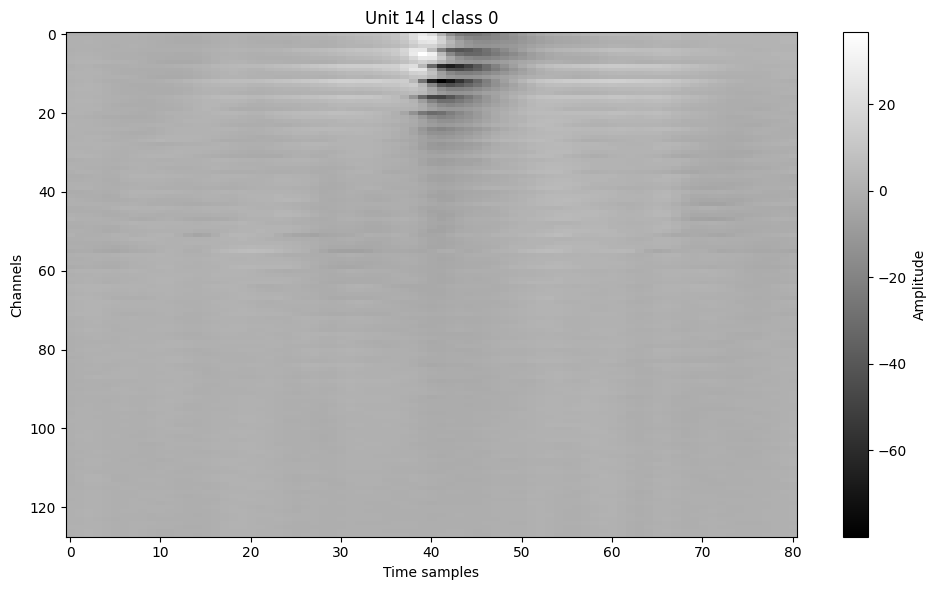

In [66]:
class_id = 0


waveform = mean_waveforms_ordered[class_id]

plt.figure(figsize=(10, 6))

plt.imshow(
    waveform.T,
    aspect="auto",
    cmap="gray"
)

plt.xlabel("Time samples")
plt.ylabel("Channels")
plt.title(
    f"Unit {class_to_unit[class_id]} | class {class_id}"
)

plt.colorbar(label="Amplitude")

plt.tight_layout()
plt.show()

In [70]:
locations = recording.get_channel_locations()

print(
    "Location array shape:",
    locations.shape
)
original_location = locations[
    peak_channel_original
]

ordered_location = locations[
    channel_order[ordered_position]
]

print(
    "Original peak channel location:",
    original_location
)

print(
    "Reordered peak channel location:",
    ordered_location
)


Location array shape: (128, 2)
Original peak channel location: [ 16. 640.]
Reordered peak channel location: [ 16. 640.]


In [76]:
BOX_THRESHOLD = 0.20

unit_boxes = {}

for class_id, unit_id in enumerate(unit_ids):

    # (time, channels)
    waveform = mean_waveforms_ordered[class_id]

    abs_waveform = np.abs(waveform)

    max_amplitude = abs_waveform.max()

    if max_amplitude == 0:
        raise ValueError(
            f"Unit {unit_id} has zero waveform amplitude."
        )

    threshold = BOX_THRESHOLD * max_amplitude

    mask = abs_waveform >= threshold

    time_idx, channel_idx = np.where(mask)

    if len(time_idx) == 0:
        raise ValueError(
            f"No pixels above threshold for unit {unit_id}."
        )

    # Peak channel
    peak_channel = np.argmax(
        abs_waveform.max(axis=0)
    )

    # Peak time on peak channel
    peak_time = np.argmax(
        abs_waveform[:, peak_channel]
    )

    t_min = time_idx.min()
    t_max = time_idx.max()

    ch_min = channel_idx.min()
    ch_max = channel_idx.max()

    unit_boxes[class_id] = {
        "unit_id": int(unit_id),

        "peak_time": int(peak_time),
        "peak_channel": int(peak_channel),

        "t_min": int(t_min),
        "t_max": int(t_max),

        "ch_min": int(ch_min),
        "ch_max": int(ch_max),

        "left": int(peak_time - t_min),
        "right": int(t_max - peak_time),

        "top": int(peak_channel - ch_min),
        "bottom": int(ch_max - peak_channel),

        "max_amplitude": float(max_amplitude),
        "threshold": float(threshold),
    }

print("Boxes calculated:", len(unit_boxes))

Boxes calculated: 100


In [77]:
box_widths = np.array([
    box["t_max"] - box["t_min"] + 1
    for box in unit_boxes.values()
])

box_heights = np.array([
    box["ch_max"] - box["ch_min"] + 1
    for box in unit_boxes.values()
])

print("Temporal box width")
print(
    "  min:",
    box_widths.min()
)
print(
    "  max:",
    box_widths.max()
)
print(
    "  mean:",
    box_widths.mean()
)

print()

print("Spatial box height")
print(
    "  min:",
    box_heights.min()
)
print(
    "  max:",
    box_heights.max()
)
print(
    "  mean:",
    box_heights.mean()
)
print(
    "Boxes covering >75% of time:"
)

for class_id, box in unit_boxes.items():

    width = (
        box["t_max"]
        - box["t_min"]
        + 1
    )

    height = (
        box["ch_max"]
        - box["ch_min"]
        + 1
    )

    if (
        width > 0.75 * 81
        or
        height > 0.75 * 128
    ):
        print(
            f"class {class_id} | "
            f"unit {box['unit_id']} | "
            f"size {width} × {height}"
        )


Temporal box width
  min: 7
  max: 55
  mean: 34.02

Spatial box height
  min: 10
  max: 61
  mean: 30.19
Boxes covering >75% of time:


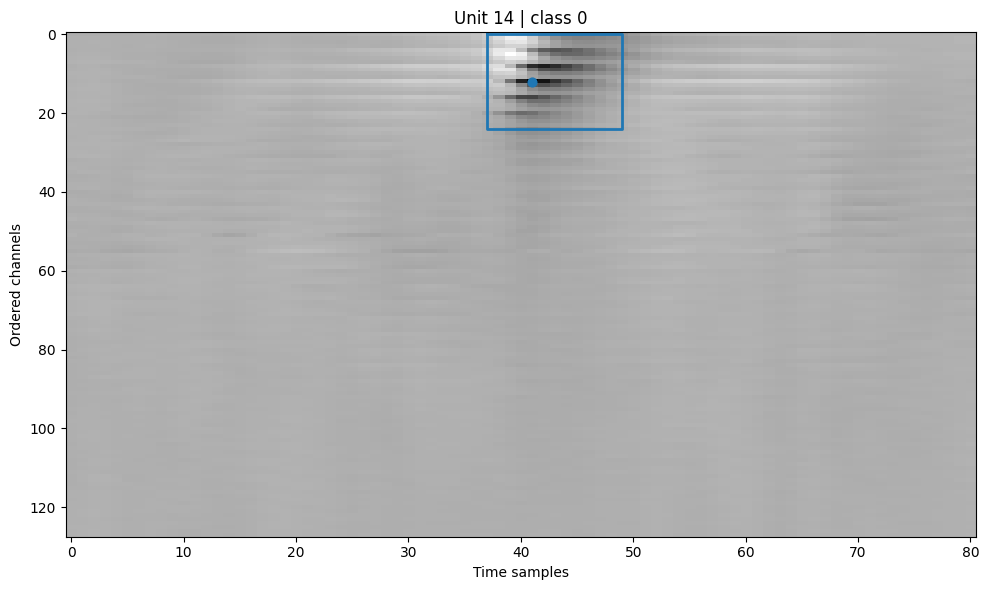

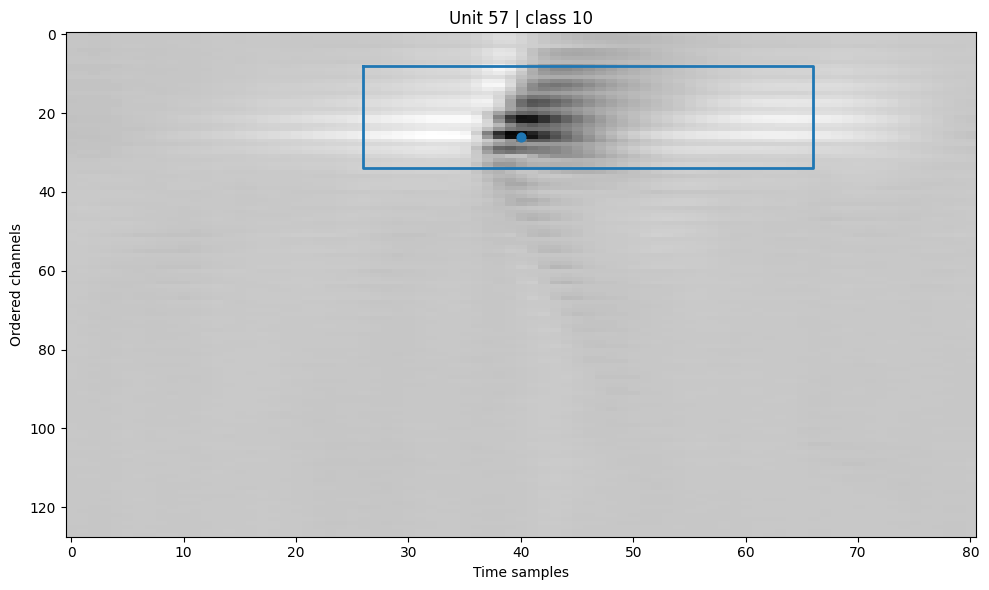

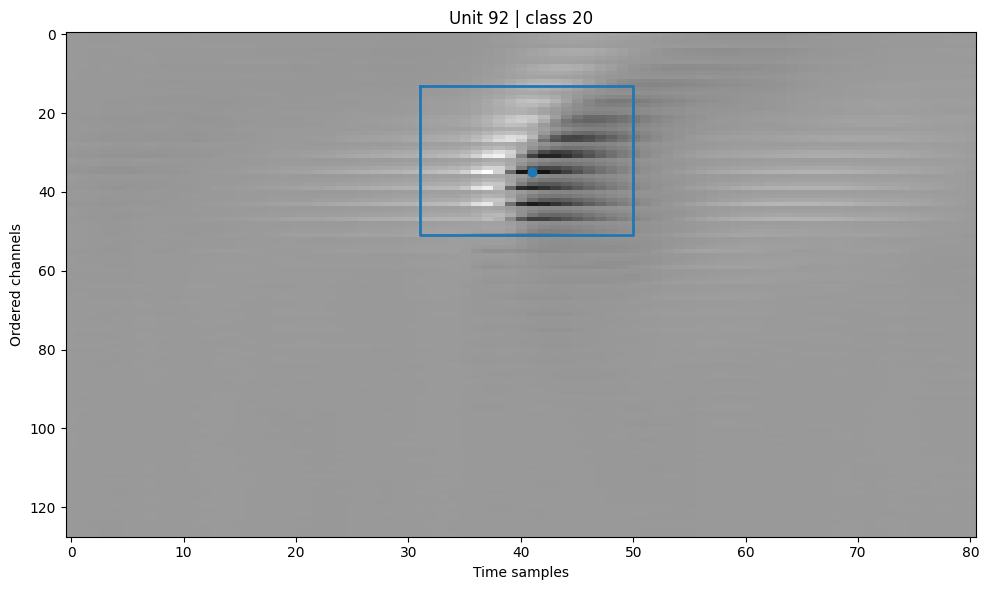

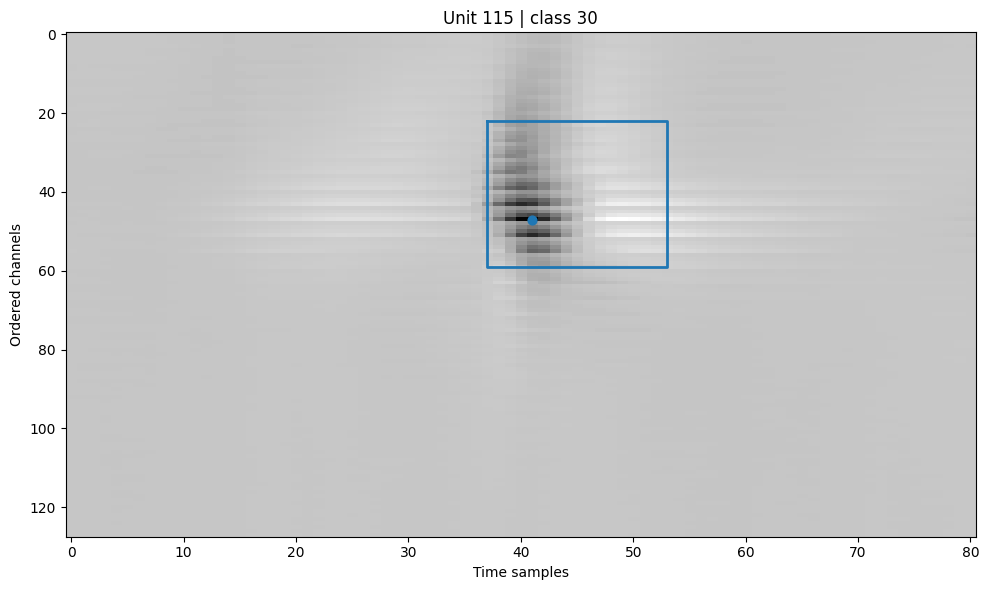

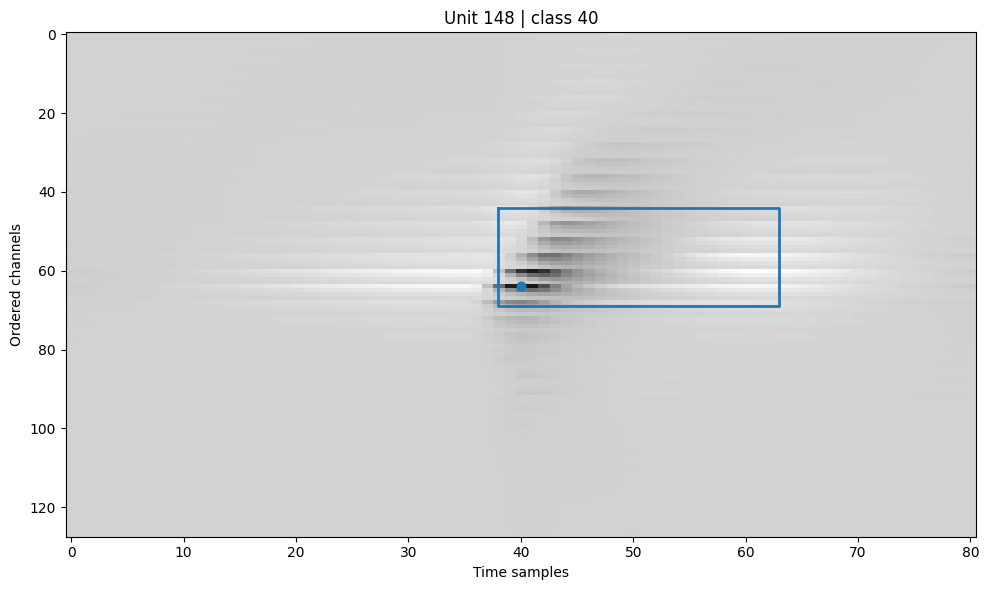

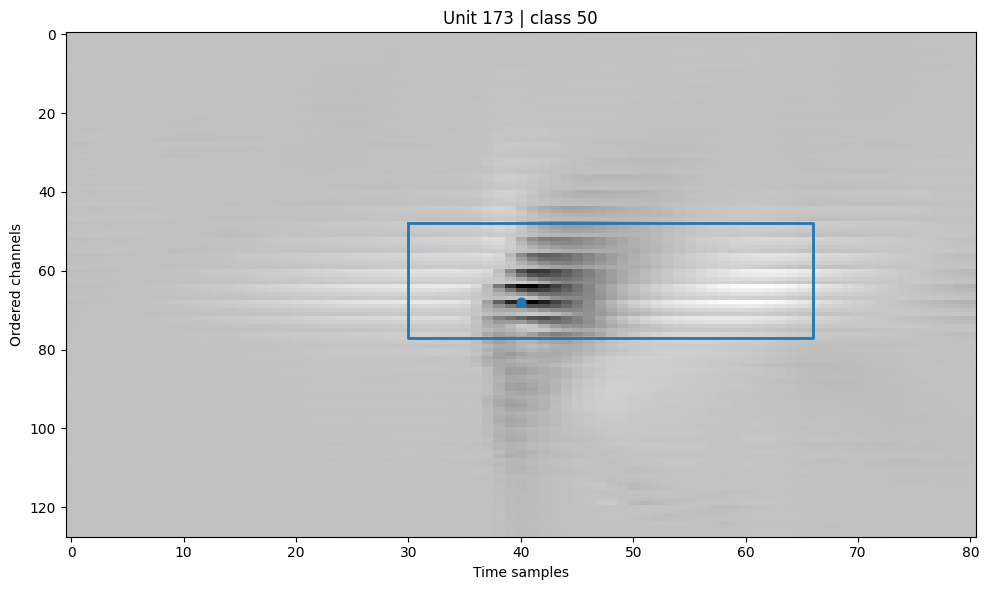

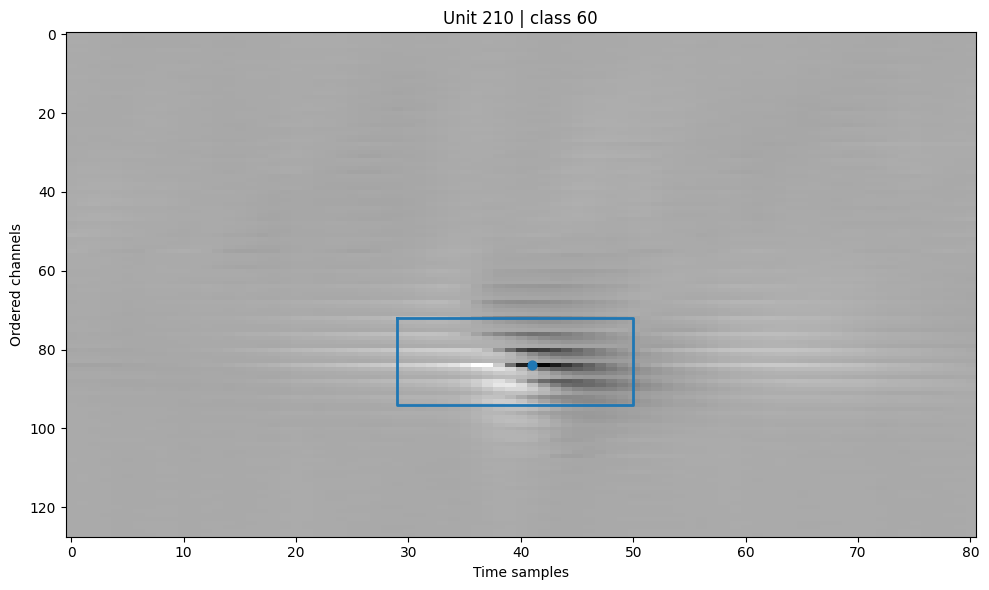

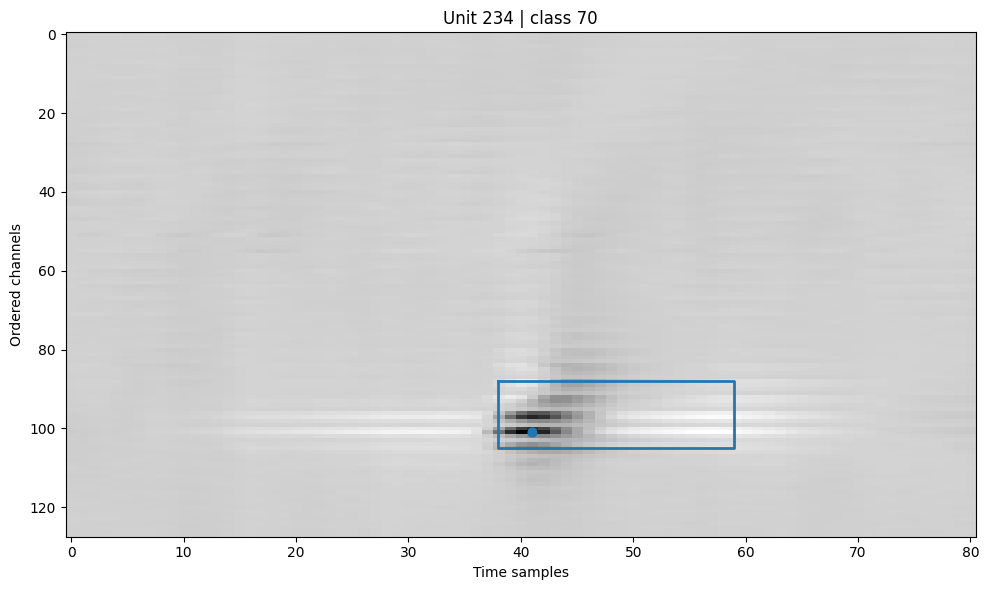

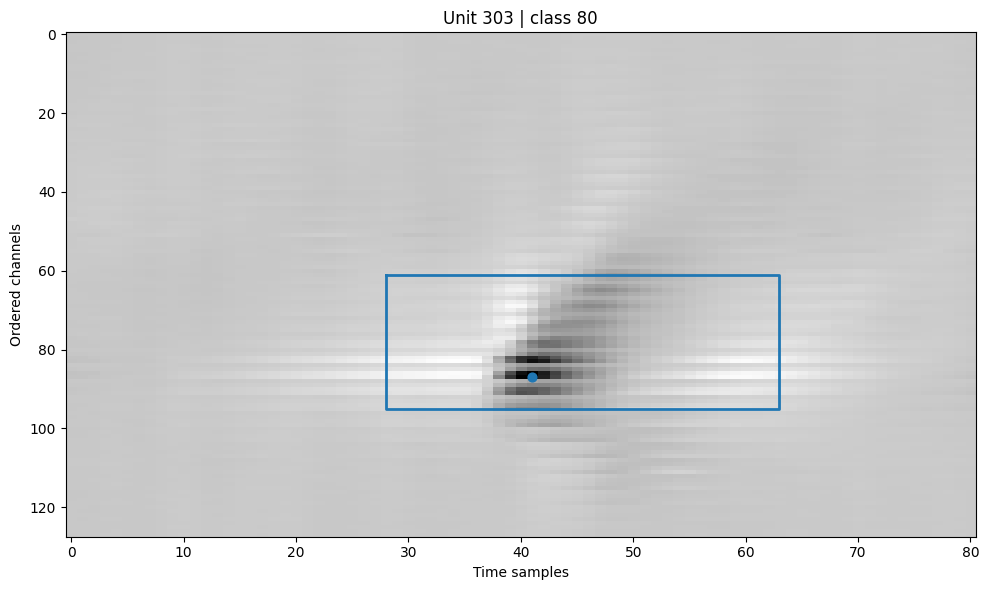

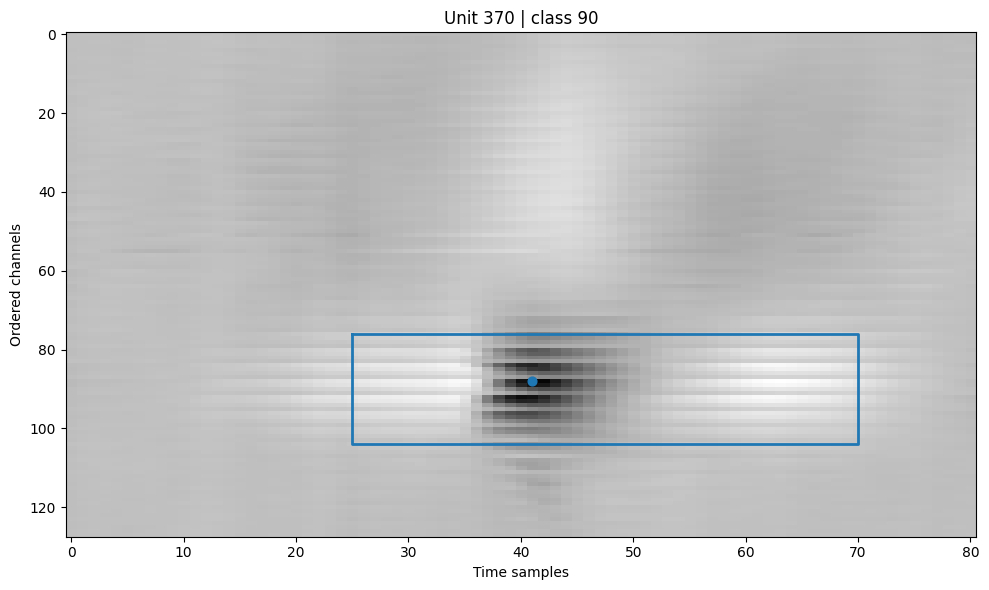

In [78]:
def plot_template_with_box(
    class_id
):

    waveform = (
        mean_waveforms_ordered[
            class_id
        ]
    )

    box = unit_boxes[
        class_id
    ]

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    ax.imshow(
        waveform.T,
        aspect="auto",
        cmap="gray"
    )

    x1 = box["t_min"]
    x2 = box["t_max"]

    y1 = box["ch_min"]
    y2 = box["ch_max"]

    ax.plot(
        [x1, x2, x2, x1, x1],
        [y1, y1, y2, y2, y1],
        linewidth=2
    )

    ax.scatter(
        box["peak_time"],
        box["peak_channel"],
        s=40
    )

    ax.set_xlabel(
        "Time samples"
    )

    ax.set_ylabel(
        "Ordered channels"
    )

    ax.set_title(
        f"Unit {box['unit_id']} | "
        f"class {class_id}"
    )

    plt.tight_layout()
    plt.show()
for class_id in [
    0, 10, 20, 30, 40,
    50, 60, 70, 80, 90
]:
    plot_template_with_box(
        class_id
    )

In [80]:
IMAGE_SIZE = 128

ORIGINAL_TIME = 81

time_scale = (
    IMAGE_SIZE /
    ORIGINAL_TIME
)

print(
    "Time scaling factor:",
    time_scale
)

Time scaling factor: 1.5802469135802468


In [81]:
def waveform_to_image(
    waveform
):

    # (time, channel)
    # ->
    # (channel, time)

    image = waveform.T.astype(
        np.float32
    )

    assert image.shape == (
        128,
        81
    )

    max_abs = np.max(
        np.abs(image)
    )

    if max_abs == 0:
        raise ValueError(
            "Zero-amplitude waveform."
        )

    # Symmetric normalization
    image = image / max_abs

    # Resize:
    # height = channels = 128
    # width  = time = 81 -> 128

    image = cv2.resize(
        image,
        (
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )

    # [-1, +1] -> [0, 255]

    image = (
        (image + 1.0)
        * 0.5
        * 255.0
    )

    image = np.clip(
        image,
        0,
        255
    ).astype(
        np.uint8
    )

    return image

In [82]:
for class_id in range(10):

    box = unit_boxes[class_id]

    print(
        f"class {class_id:3d} | "
        f"unit {box['unit_id']:4d} | "
        f"time: {box['t_min']:2d}-{box['t_max']:2d} | "
        f"channels: {box['ch_min']:3d}-{box['ch_max']:3d} | "
        f"peak: ({box['peak_time']:2d}, {box['peak_channel']:3d})"
    )

class   0 | unit   14 | time: 37-49 | channels:   0- 24 | peak: (41,  12)
class   1 | unit   19 | time: 24-69 | channels:   1- 15 | peak: (41,   7)
class   2 | unit   27 | time: 34-56 | channels:   5- 19 | peak: (41,  11)
class   3 | unit   30 | time: 28-61 | channels:   0- 21 | peak: (41,  12)
class   4 | unit   31 | time: 25-69 | channels:   0- 40 | peak: (41,  12)
class   5 | unit   41 | time: 27-65 | channels:   0- 29 | peak: (40,  12)
class   6 | unit   44 | time: 26-68 | channels:   1- 27 | peak: (41,  15)
class   7 | unit   53 | time: 28-66 | channels:   1- 31 | peak: (41,  19)
class   8 | unit   54 | time: 29-63 | channels:   6- 23 | peak: (40,  19)
class   9 | unit   55 | time: 27-47 | channels:   8- 28 | peak: (40,  20)


In [83]:
test_image = waveform_to_image(
    mean_waveforms_ordered[0]
)

print(
    "Shape:",
    test_image.shape
)

print(
    "Dtype:",
    test_image.dtype
)

print(
    "Range:",
    test_image.min(),
    test_image.max()
)

Shape: (128, 128)
Dtype: uint8
Range: 1 185


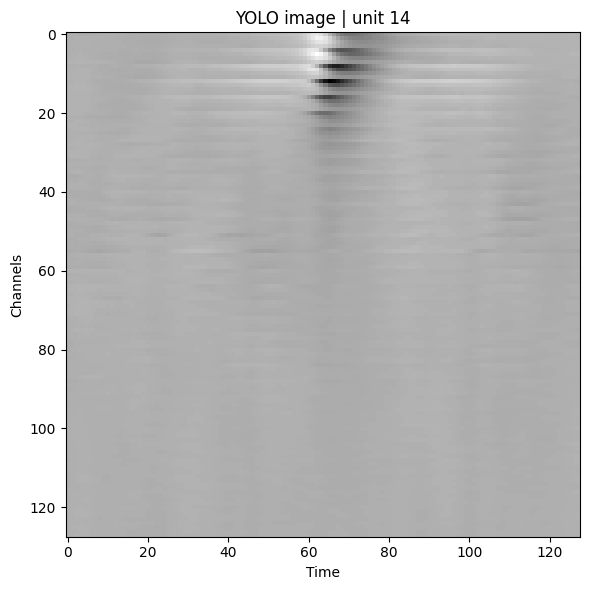

In [84]:
plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    test_image,
    cmap="gray",
    aspect="auto"
)

plt.xlabel("Time")
plt.ylabel("Channels")

plt.title(
    f"YOLO image | "
    f"unit {unit_ids[0]}"
)

plt.tight_layout()
plt.show()

In [ ]:
def box_to_resized_coordinates(
    box
):

    x1 = (
        box["t_min"]
        * time_scale
    )

    x2 = (
        (box["t_max"] + 1)
        * time_scale
    )

    y1 = box["ch_min"]

    y2 = (
        box["ch_max"] + 1
    )

    x1 = np.clip(
        x1,
        0,
        IMAGE_SIZE
    )

    x2 = np.clip(
        x2,
        0,
        IMAGE_SIZE
    )

    y1 = np.clip(
        y1,
        0,
        IMAGE_SIZE
    )

    y2 = np.clip(
        y2,
        0,
        IMAGE_SIZE
    )

    return (
        x1,
        y1,
        x2,
        y2
    )
class_id = 0



def box_to_yolo(
    box
):

    x1, y1, x2, y2 = (
        box_to_resized_coordinates(
            box
        )
    )

    x_center = (
        (x1 + x2) / 2
    ) / IMAGE_SIZE

    y_center = (
        (y1 + y2) / 2
    ) / IMAGE_SIZE

    width = (
        x2 - x1
    ) / IMAGE_SIZE

    height = (
        y2 - y1
    ) / IMAGE_SIZE

    return (
        x_center,
        y_center,
        width,
        height
    )



yolo_box = box_to_yolo(
    unit_boxes[class_id]
)

print(
    "Class:",
    class_id
)

print(
    "Unit:",
    class_to_unit[class_id]
)

print(
    "YOLO box:",
    yolo_box
)

assert all(
    0 <= value <= 1
    for value in yolo_box
)

print(
    "YOLO box is valid."
)

Class: 0
Unit: 14
YOLO box: (np.float64(0.537037037037037), np.float64(0.09765625), np.float64(0.16049382716049382), np.float64(0.1953125))
YOLO box is valid.


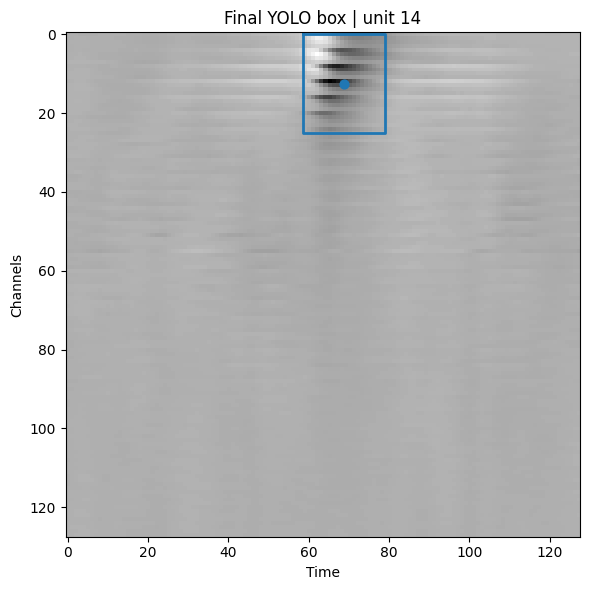

In [90]:
class_id = 0

image = waveform_to_image(
    mean_waveforms_ordered[
        class_id
    ]
)

x_center, y_center, width, height = (
    box_to_yolo(
        unit_boxes[class_id]
    )
)

x1 = (
    x_center - width / 2
) * IMAGE_SIZE

x2 = (
    x_center + width / 2
) * IMAGE_SIZE

y1 = (
    y_center - height / 2
) * IMAGE_SIZE

y2 = (
    y_center + height / 2
) * IMAGE_SIZE

plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    image,
    cmap="gray",
    aspect="auto"
)

plt.plot(
    [x1, x2, x2, x1, x1],
    [y1, y1, y2, y2, y1],
    linewidth=2
)

plt.scatter(
    x_center * IMAGE_SIZE,
    y_center * IMAGE_SIZE,
    s=40
)

plt.xlabel("Time")
plt.ylabel("Channels")

plt.title(
    f"Final YOLO box | "
    f"unit {unit_ids[class_id]}"
)

plt.tight_layout()
plt.show()

In [91]:
images_train = (
    dataset_path /
    "images" /
    "train"
)

images_val = (
    dataset_path /
    "images" /
    "val"
)

labels_train = (
    dataset_path /
    "labels" /
    "train"
)

labels_val = (
    dataset_path /
    "labels" /
    "val"
)

for folder in [
    images_train,
    images_val,
    labels_train,
    labels_val
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print(
    "YOLO directories created."
)

YOLO directories created.


In [115]:
for class_id, unit_id in enumerate(
    unit_ids
):

    waveform = (
        mean_waveforms_ordered[
            class_id
        ]
    )

    # Create image
    image = waveform_to_image(
        waveform
    )

    # Create YOLO box
    yolo_box = box_to_yolo(
        unit_boxes[class_id]
    )

    filename = (
        f"class_{class_id:03d}.png"
    )

    # Save image in train
    cv2.imwrite(
        str(
            images_train /
            filename
        ),
        image
    )

    # Save same image in val
    cv2.imwrite(
        str(
            images_val /
            filename
        ),
        image
    )

    # Label filename
    label_filename = (
        f"class_{class_id:03d}.txt"
    )

    label_text = (
        f"{class_id} "
        f"{yolo_box[0]:.6f} "
        f"{yolo_box[1]:.6f} "
        f"{yolo_box[2]:.6f} "
        f"{yolo_box[3]:.6f}\n"
    )

    # Train label
    with open(
        labels_train /
        label_filename,
        "w"
    ) as f:
        f.write(
            label_text
        )

    # Validation label
    with open(
        labels_val /
        label_filename,
        "w"
    ) as f:
        f.write(
            label_text
        )

print(
    "Generated 100 images "
    "and 100 labels."
)
train_image_stems = {
    p.stem
    for p in train_images
}

train_label_stems = {
    p.stem
    for p in train_labels
}

val_image_stems = {
    p.stem
    for p in val_images
}

val_label_stems = {
    p.stem
    for p in val_labels
}

assert (
    train_image_stems ==
    train_label_stems
)

assert (
    val_image_stems ==
    val_label_stems
)

assert (
    train_image_stems ==
    val_image_stems
)

print(
    "Image/label matching verified."
)

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x149a40dd0>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 3204bcad0, raw_cell="for class_id, unit_id in enumerate(
    unit_ids
).." transformed_cell="for class_id, unit_id in enumerate(
    unit_ids
).." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/Zita/Documents/EGYETEM/%C3%96nlab/yolo26/test%20training.ipynb#X42sZmlsZQ%3D%3D>,),kwargs {}:


ConnectionResetError: Connection lost

Generated 100 images and 100 labels.
Image/label matching verified.
Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x149a40dd0>> (for post_run_cell), with arguments args (<ExecutionResult object at 320bc8650, execution_count=115 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 3204bcad0, raw_cell="for class_id, unit_id in enumerate(
    unit_ids
).." transformed_cell="for class_id, unit_id in enumerate(
    unit_ids
).." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/Zita/Documents/EGYETEM/%C3%96nlab/yolo26/test%20training.ipynb#X42sZmlsZQ%3D%3D> result=None>,),kwargs {}:


ConnectionResetError: Connection lost

In [116]:
yaml_path = (
    dataset_path /
    "data.yaml"
)

with open(
    yaml_path,
    "w"
) as f:

    f.write(
        f"path: "
        f"{dataset_path.resolve()}\n"
    )

    f.write(
        "train: images/train\n"
    )

    f.write(
        "val: images/val\n"
    )

    f.write(
        "nc: 100\n"
    )

    f.write(
        "names:\n"
    )

    for class_id, unit_id in enumerate(
        unit_ids
    ):

        f.write(
            f"  {class_id}: "
            f"unit_{int(unit_id)}\n"
        )

print(
    yaml_path.read_text()
)

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x149a40dd0>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 320197690, raw_cell="yaml_path = (
    dataset_path /
    "data.yaml"
).." transformed_cell="yaml_path = (
    dataset_path /
    "data.yaml"
).." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/Zita/Documents/EGYETEM/%C3%96nlab/yolo26/test%20training.ipynb#X45sZmlsZQ%3D%3D>,),kwargs {}:


ConnectionResetError: Connection lost

path: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26_mean_waveform_overfit
train: images/train
val: images/val
nc: 100
names:
  0: unit_14
  1: unit_19
  2: unit_27
  3: unit_30
  4: unit_31
  5: unit_41
  6: unit_44
  7: unit_53
  8: unit_54
  9: unit_55
  10: unit_57
  11: unit_60
  12: unit_63
  13: unit_72
  14: unit_77
  15: unit_78
  16: unit_87
  17: unit_88
  18: unit_89
  19: unit_90
  20: unit_92
  21: unit_93
  22: unit_99
  23: unit_100
  24: unit_104
  25: unit_105
  26: unit_106
  27: unit_108
  28: unit_109
  29: unit_114
  30: unit_115
  31: unit_116
  32: unit_117
  33: unit_119
  34: unit_120
  35: unit_129
  36: unit_134
  37: unit_135
  38: unit_136
  39: unit_145
  40: unit_148
  41: unit_149
  42: unit_151
  43: unit_153
  44: unit_154
  45: unit_155
  46: unit_162
  47: unit_164
  48: unit_168
  49: unit_172
  50: unit_173
  51: unit_177
  52: unit_178
  53: unit_183
  54: unit_185
  55: unit_196
  56: unit_198
  57: unit_201
  58: unit_202
  59: unit_204
  6

ConnectionResetError: Connection lost

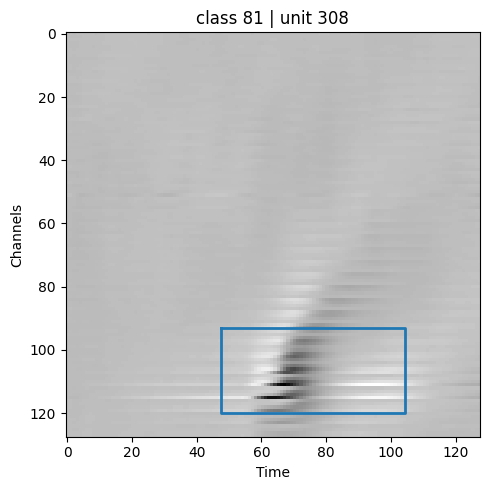

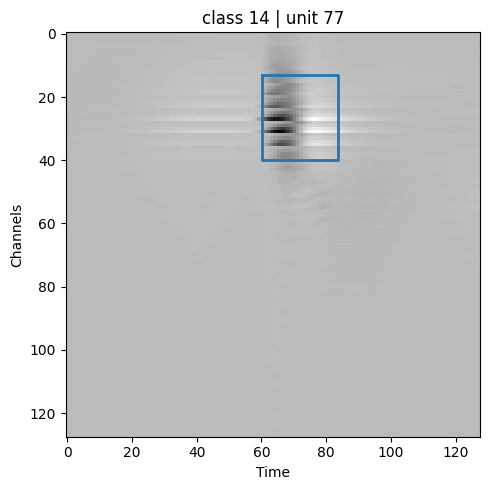

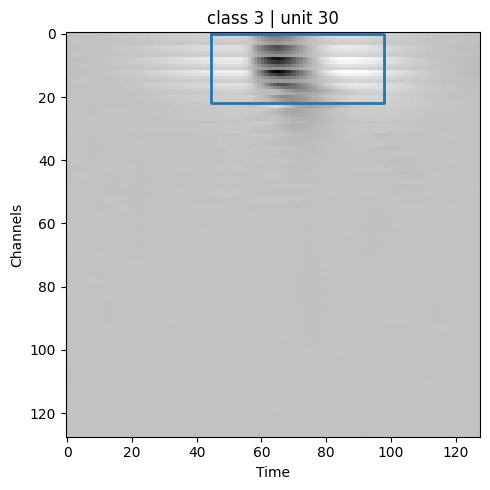

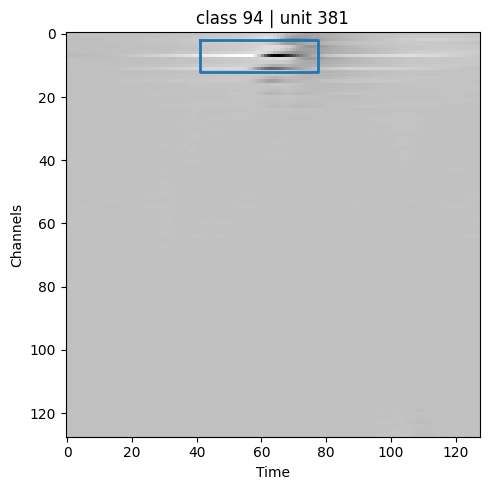

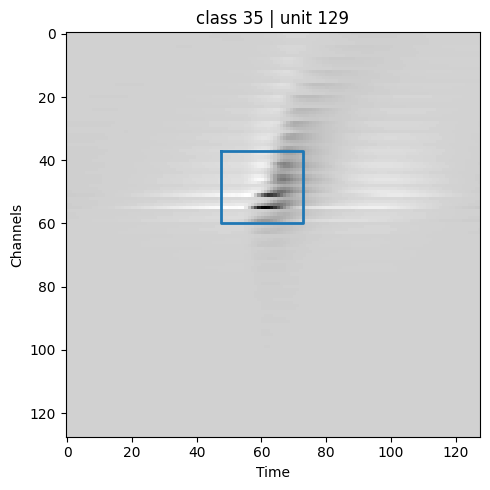

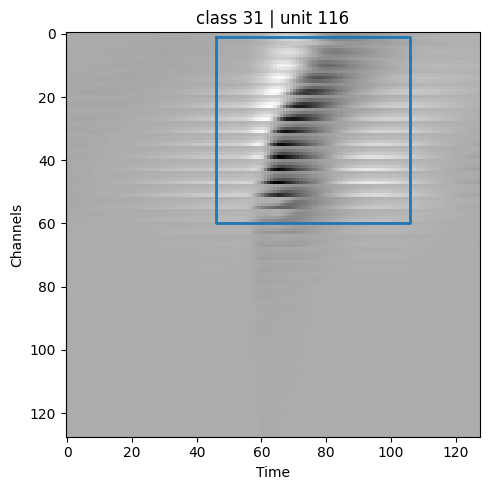

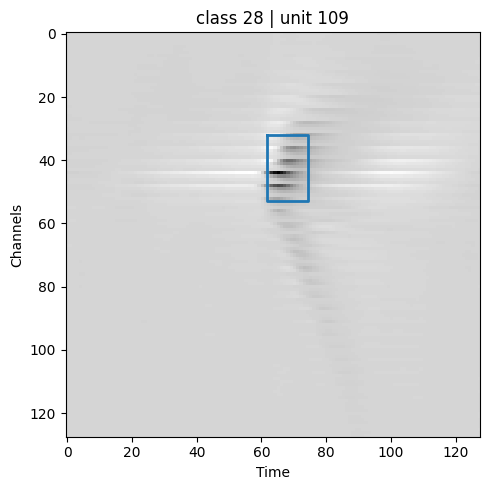

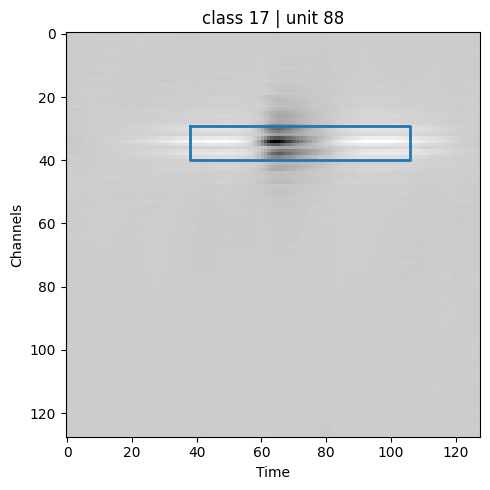

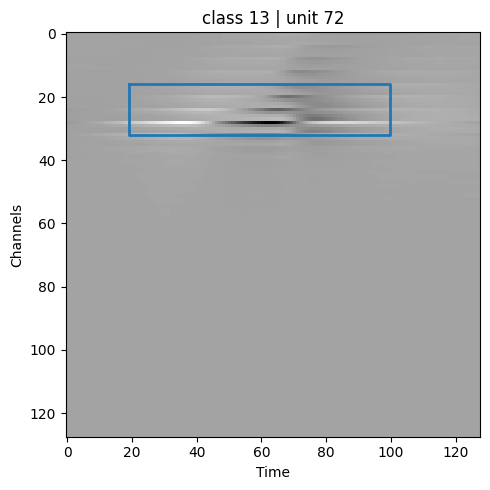

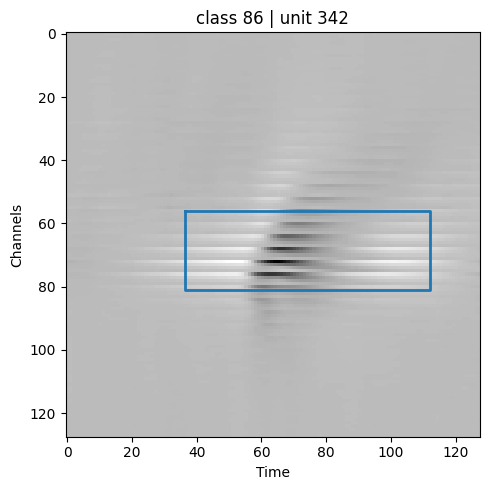

In [100]:
import random

random.seed(42)

classes_to_check = random.sample(
    range(100),
    10
)

for class_id in classes_to_check:

    image_path = (
        images_train /
        f"class_{class_id:03d}.png"
    )

    label_path = (
        labels_train /
        f"class_{class_id:03d}.txt"
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    label = np.loadtxt(
        label_path
    )

    _, xc, yc, w, h = label

    x1 = (
        xc - w / 2
    ) * IMAGE_SIZE

    x2 = (
        xc + w / 2
    ) * IMAGE_SIZE

    y1 = (
        yc - h / 2
    ) * IMAGE_SIZE

    y2 = (
        yc + h / 2
    ) * IMAGE_SIZE

    plt.figure(
        figsize=(5, 5)
    )

    plt.imshow(
        image,
        cmap="gray",
        aspect="auto"
    )

    plt.plot(
        [x1, x2, x2, x1, x1],
        [y1, y1, y2, y2, y1],
        linewidth=2
    )

    plt.title(
        f"class {class_id} | "
        f"unit {class_to_unit[class_id]}"
    )

    plt.xlabel("Time")
    plt.ylabel("Channels")

    plt.tight_layout()
    plt.show()

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data=str(yaml_path),
    imgsz=128,
    epochs=500,
    batch=16,
    seed=42,

    augment=False,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,

    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,

    flipud=0.0,
    fliplr=0.0,

    mosaic=0.0,
    mixup=0.0,
    cutmix=0.0,
    close_mosaic=0,
    workers=0,
    cache=True,
    patience=50,

    # W&B / experiment naming
    project="spike_yolo_overfit",
    name="mean_waveforms_100_test",

    # Validation
    val=True,
)

Error in callback <bound method _WandbInit._pre_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x149a40dd0>> (for pre_run_cell), with arguments args (<ExecutionInfo object at 306979310, raw_cell="from ultralytics import YOLO

model = YOLO("yolo26.." transformed_cell="from ultralytics import YOLO

model = YOLO("yolo26.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/Zita/Documents/EGYETEM/%C3%96nlab/yolo26/test%20training.ipynb#X53sZmlsZQ%3D%3D>,),kwargs {}:


ConnectionResetError: Connection lost

New https://pypi.org/project/ultralytics/8.4.128 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.84 🚀 Python-3.11.15 torch-2.11.0 CPU (Apple M3 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26_mean_waveform_overfit/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=500, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=128, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.

ConnectionResetError: Connection lost

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x149a40dd0>> (for post_run_cell), with arguments args (<ExecutionResult object at 305d89790, execution_count=106 error_before_exec=None error_in_exec=Connection lost info=<ExecutionInfo object at 306979310, raw_cell="from ultralytics import YOLO

model = YOLO("yolo26.." transformed_cell="from ultralytics import YOLO

model = YOLO("yolo26.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/Users/Zita/Documents/EGYETEM/%C3%96nlab/yolo26/test%20training.ipynb#X53sZmlsZQ%3D%3D> result=None>,),kwargs {}:


ConnectionResetError: Connection lost